In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from preprocessing import crop_frame

In [2]:
frame_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\sample_frames\frame_0129.png"

frame = crop_frame(cv2.imread(frame_path))                 # cropped: 1350 x 1080
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(int)
h, w = gray.shape


# black reference (Method 2): median of the four 5x5 corner blocks, always inside the black triangles
black_ref = int(np.median(np.concatenate([gray[:5, :5].ravel(), gray[:5, -5:].ravel(),
                                          gray[-5:, :5].ravel(), gray[-5:, -5:].ravel()])))
print(f"cropped frame: {w} x {h}   black reference: {black_ref}")



cropped frame: 1350 x 1080   black reference: 15


In [3]:
def edges_method1(line, thresh=30, run=15):
    """Crop Method 1 on any 1-D line (a row or a column): first / last position where
    `run` consecutive pixels are all >= thresh. Returns (start, end) as positions on the line."""
    n = len(line)
    start = end = None
    for i in range(0, n - run + 1):
        if (line[i:i + run] >= thresh).all():
            start = i
            break
    for i in range(n - 1, run - 2, -1):
        if (line[i - run + 1:i + 1] >= thresh).all():
            end = i
            break
    return start, end


def edges_method2(line, black_ref, delta=20):
    """Crop Method 2 on any 1-D line: first / last position whose value differs
    from the black reference by more than delta."""
    n = len(line)
    start = end = None
    for i in range(n):
        if abs(int(line[i]) - black_ref) > delta:
            start = i
            break
    for i in range(n - 1, -1, -1):
        if abs(int(line[i]) - black_ref) > delta:
            end = i
            break
    return start, end

In [4]:
def inspect_line(kind="row", index=0, window=10):
    """Look at one row or column yourself: where it sits on the frame, its brightness
    profile, and the raw pixel values around each detected edge."""
    line = gray[index, :] if kind == "row" else gray[:, index]
    pos = "x" if kind == "row" else "y"
    s1, e1 = edges_method1(line)
    s2, e2 = edges_method2(line, black_ref)
    print(f"{kind} {index}: length={len(line)}  min={line.min()}  max={line.max()}")
    print(f"  Method 1 -> start {pos}={s1}, end {pos}={e1}")
    print(f"  Method 2 -> start {pos}={s2}, end {pos}={e2}")

    for label, edge in [("start", s1), ("end", e1)]:
        if edge is None:
            print(f"\n  no {label} edge found")
            continue
        lo, hi = max(edge - window, 0), min(edge + window + 1, len(line))
        print(f"\n  values around the {label} edge ({pos}={lo}..{hi-1}):")
        print("   " + "  ".join(f"{i}:{line[i]}" for i in range(lo, hi)))

    fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2]})
    ax[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    if kind == "row":
        ax[0].axhline(index, color="blue", lw=2)
    else:
        ax[0].axvline(index, color="blue", lw=2)
    ax[0].set_title(f"blue = {kind} {index}"); ax[0].axis("off")
    ax[1].plot(line)
    ax[1].axhline(30, color="red", ls="--", label="Method 1 threshold = 30")
    ax[1].axhline(black_ref + 20, color="orange", ls="--", label=f"Method 2: black_ref + 20 = {black_ref + 20}")
    ax[1].set_xlabel(f"{pos} (position along the {kind})"); ax[1].set_ylabel("grayscale value")
    ax[1].set_title(f"brightness along {kind} {index}"); ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()




column 1349: length=1080  min=9  max=132
  Method 1 -> start y=251, end y=828
  Method 2 -> start y=251, end y=828

  values around the start edge (y=241..261):
   241:15  242:15  243:15  244:15  245:15  246:14  247:14  248:10  249:9  250:24  251:37  252:106  253:110  254:111  255:111  256:111  257:111  258:111  259:111  260:111  261:111

  values around the end edge (y=818..838):
   818:93  819:93  820:93  821:93  822:94  823:95  824:94  825:94  826:96  827:90  828:51  829:24  830:18  831:16  832:15  833:15  834:16  835:16  836:15  837:15  838:15


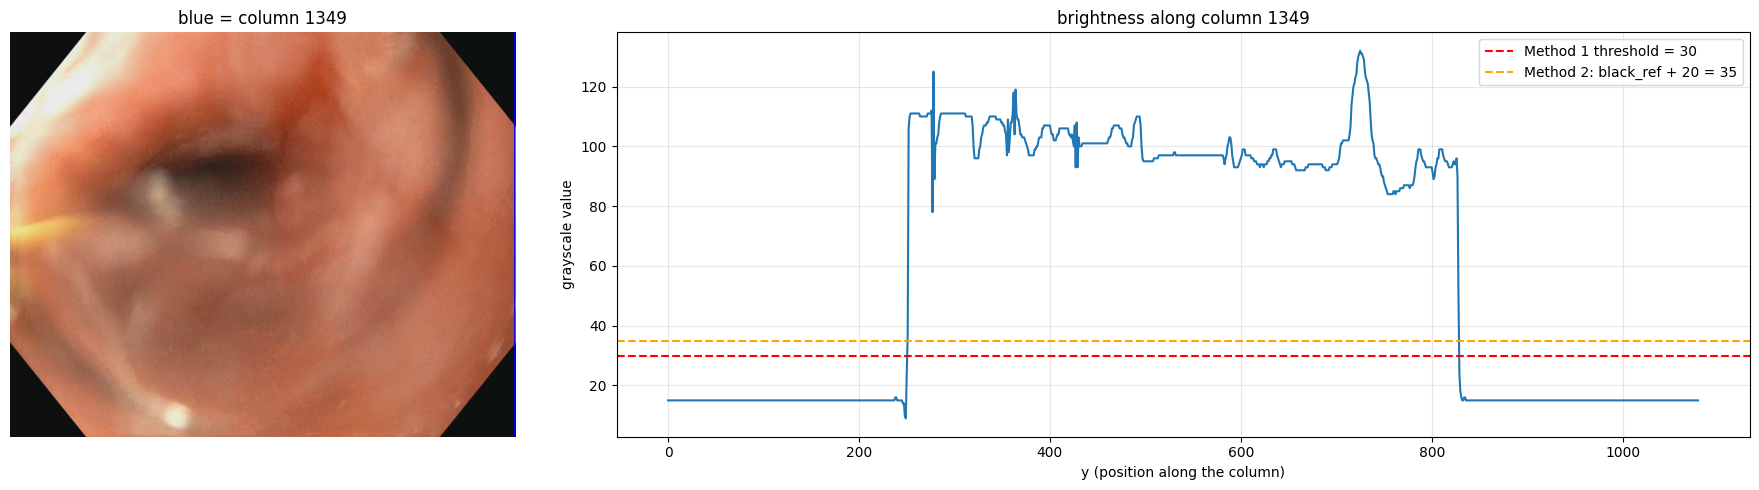

In [7]:
inspect_line("column", 1349)          # change to e.g. ("row", 1079), ("column", 0), ("column", 1349), ("row", 5) ...

line                 | M1 start  M1 end | M2 start  M2 end
row 0 (top)          |      203    1146 |      203    1146
row 1079 (bottom)    |      202    1147 |      202    1147
column 0 (left)      |      252     828 |      252     828
column 1349 (right)  |      251     828 |      251     828

octagon corner points (x, y): [(203, 0), (1146, 0), (1349, 251), (1349, 828), (1147, 1079), (202, 1079), (0, 828), (0, 252)]


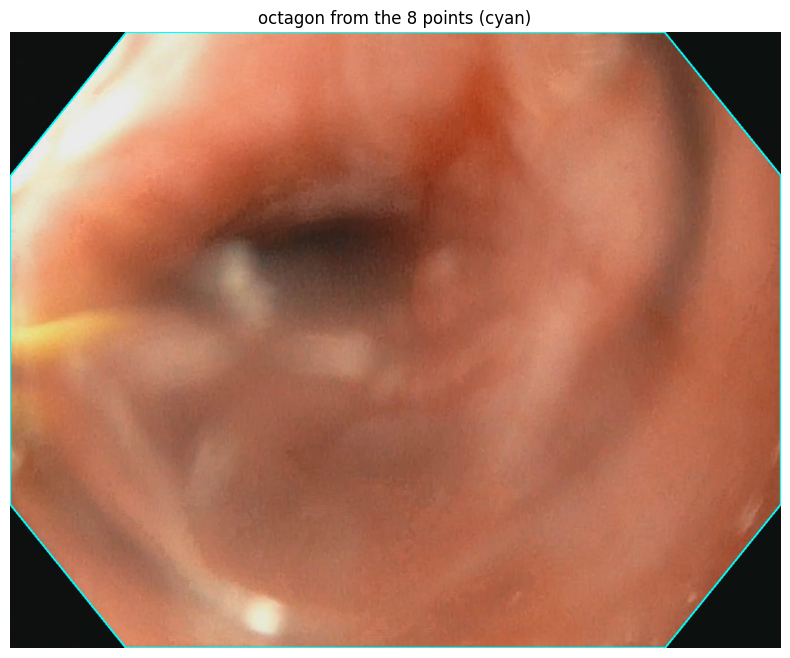

In [8]:
def octagon_points(gray, black_ref):
    """Scan the four boundary lines of the cropped frame with both methods and
    return the octagon's 8 corner points (x, y) in cropped-frame coordinates."""
    h, w = gray.shape
    lines = {
        "row 0 (top)":            gray[0, :],
        f"row {h-1} (bottom)":    gray[h - 1, :],
        "column 0 (left)":        gray[:, 0],
        f"column {w-1} (right)":  gray[:, w - 1],
    }
    found = {}
    print(f"{'line':<20} | {'M1 start':>8} {'M1 end':>7} | {'M2 start':>8} {'M2 end':>7}")
    for name, line in lines.items():
        m1, m2 = edges_method1(line), edges_method2(line, black_ref)
        print(f"{name:<20} | {str(m1[0]):>8} {str(m1[1]):>7} | {str(m2[0]):>8} {str(m2[1]):>7}")
        found[name] = m1                                   # Method 1 values used for the points

    top, bottom = found["row 0 (top)"], found[f"row {h-1} (bottom)"]
    left, right = found["column 0 (left)"], found[f"column {w-1} (right)"]
    points = [(top[0], 0), (top[1], 0),                    # along the top, left to right
              (w - 1, right[0]), (w - 1, right[1]),        # down the right side
              (bottom[1], h - 1), (bottom[0], h - 1),      # along the bottom, right to left
              (0, left[1]), (0, left[0])]                  # up the left side
    return points


points = octagon_points(gray, black_ref)
print("\noctagon corner points (x, y):", points)

vis = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB).copy()
cv2.polylines(vis, [np.array(points, np.int32)], isClosed=True, color=(0, 255, 255), thickness=2)
plt.figure(figsize=(10, 8)); plt.imshow(vis); plt.title("octagon from the 8 points (cyan)")
plt.axis("off"); plt.show()

In [9]:
202 1147
202 1147
252 828
252 828


SyntaxError: invalid syntax (2241303892.py, line 1)

In [ ]:
204 1145
204 1145
254 826
254 826

In [10]:
# Octagon mask points, cropped-frame coordinates (Decision_Log.md, Decision 12):
# measured octagon (202/1147, 252/828) pulled in 8 px from the border.
MASK_TOP_X = (213, 1136)      # start / end x on row 0 and on the last row
MASK_SIDE_Y = (265, 815)      # rows where the corner cuts end on column 0 and on the last column


def octagon_mask(height=1080, width=1350, top_x=MASK_TOP_X, side_y=MASK_SIDE_Y):
    """Boolean mask of the usable image area inside the octagon, for a cropped frame
    (crop_frame output, 1350 x 1080). True = pixel used for the blur score.
    Every True pixel is at least 8 px from the octagon's black border."""
    x0, x1 = top_x
    y0, y1 = side_y
    last_x, last_y = width - 1, height - 1
    points = np.array([(x0, 0), (x1, 0),                 # top edge
                       (last_x, y0), (last_x, y1),       # right side
                       (x1, last_y), (x0, last_y),       # bottom edge
                       (0, y1), (0, y0)], np.int32)      # left side
    mask = np.zeros((height, width), np.uint8)
    cv2.fillPoly(mask, [points], 1)
    return mask.astype(bool)

cropped frame: 1350 x 1080   mask pixels: 1,344,897  (92.2% of the cropped frame)
closest mask pixel to the black border: 7.8 px


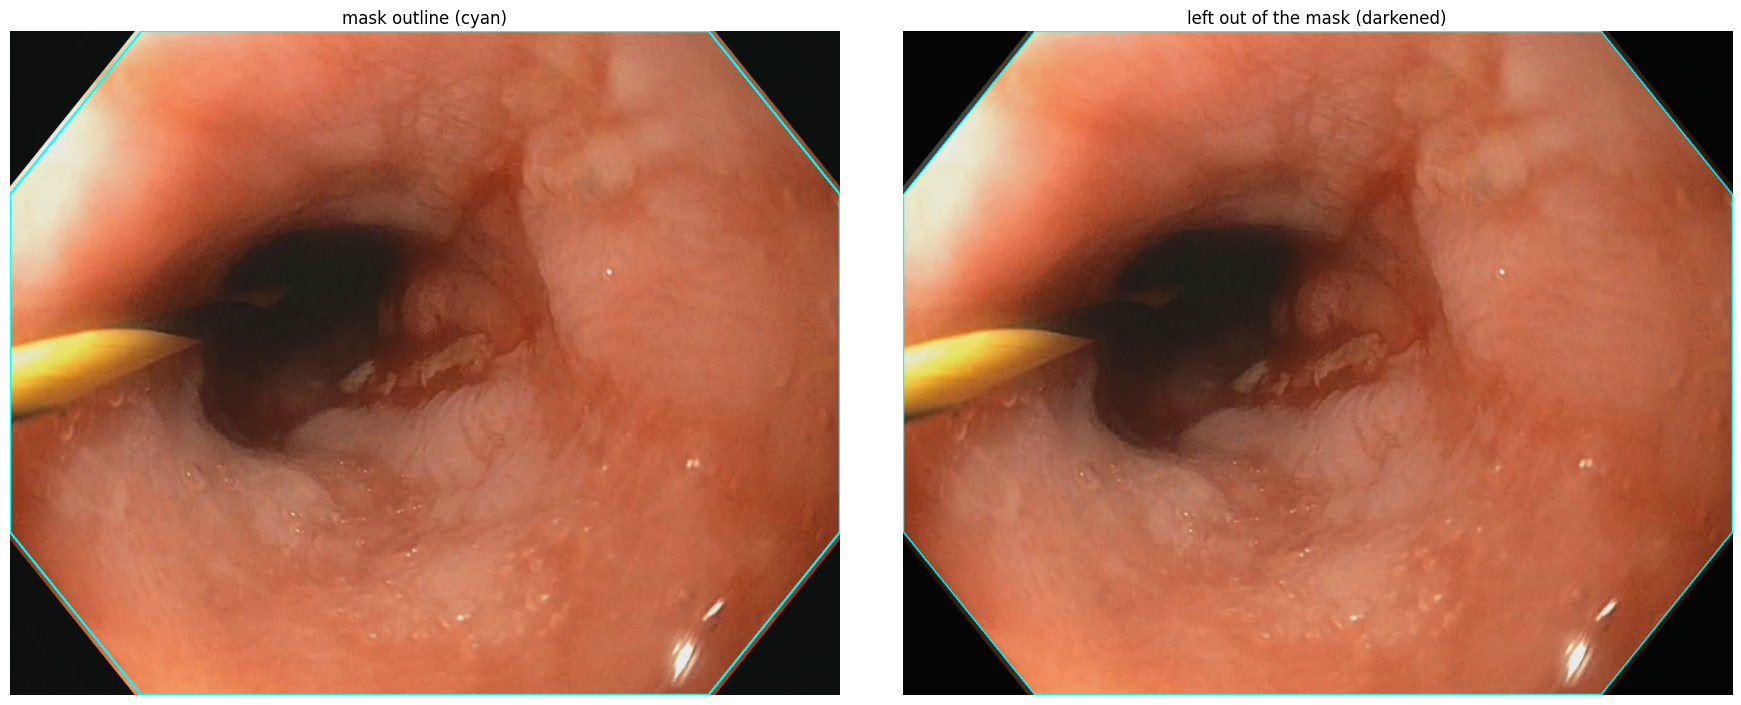

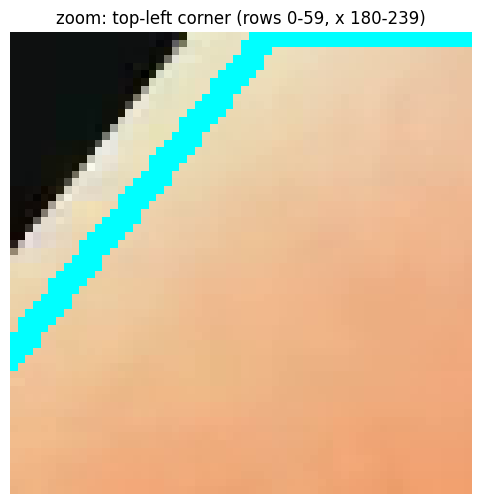

In [11]:
frame_path = r"C:\Users\ahmed\Documents\Jobs\Klinikum Oldenburg\sample_frames\frame_0259.png"

frame = crop_frame(cv2.imread(frame_path))
mask = octagon_mask(*frame.shape[:2])
print(f"cropped frame: {frame.shape[1]} x {frame.shape[0]}   mask pixels: {mask.sum():,}  "
      f"({100 * mask.mean():.1f}% of the cropped frame)")

# check: how far is the mask from the black border in this frame?
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
dark = (gray < 30).astype(np.uint8)                       # Method 1 threshold
# keep only the dark regions touching the four frame corners = the black corner triangles
# (dark tissue such as the lumen is not connected to the corners)
n, labels = cv2.connectedComponents(dark)
h, w = gray.shape
corner_labels = {labels[0, 0], labels[0, w - 1], labels[h - 1, 0], labels[h - 1, w - 1]} - {0}
border = np.isin(labels, list(corner_labels)).astype(np.uint8)
dist_from_border = cv2.distanceTransform(1 - border, cv2.DIST_L2, 5)
print(f"closest mask pixel to the black border: {dist_from_border[mask].min():.1f} px")

# show: mask outline on the frame, and the area left out
vis = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB).copy()
outline, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(vis, outline, -1, (0, 255, 255), 2)
dimmed = vis.copy()
dimmed[~mask] = (dimmed[~mask] * 0.3).astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
ax[0].imshow(vis);    ax[0].set_title("mask outline (cyan)");               ax[0].axis("off")
ax[1].imshow(dimmed); ax[1].set_title("left out of the mask (darkened)");   ax[1].axis("off")
plt.tight_layout(); plt.show()

# zoom on the top-left corner to see the 8 px gap
plt.figure(figsize=(6, 6))
plt.imshow(vis[:60, 180:240], interpolation="nearest")
plt.title("zoom: top-left corner (rows 0-59, x 180-239)"); plt.axis("off"); plt.show()

In [1]:
from preprocessing import octagon_mask
print(octagon_mask().sum())    # should print 1344897

1344897
